Import required libraries

In [167]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

import joblib

In [168]:
from pathlib import Path
import matplotlib.pyplot as plt

output_dir = Path(
    r"C:\Users\U S E R\Desktop\ML Assigment\project\output"
)

def save_plot(filename):
    plt.savefig(
        output_dir / filename,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )
    plt.show()
    plt.close()

In [169]:
processed_dir = Path(
    r"C:\Users\U S E R\Desktop\ML Assigment\project\data\processed"
)

processed_dir.mkdir(parents=True, exist_ok=True)

In [170]:
dataset_path = r"C:\Users\U S E R\Desktop\ML Assigment\project\data\raw\student-mat.csv"

df = pd.read_csv(dataset_path, sep=";")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


Understand the dataset

In [171]:
print("Column names:")
print(df.columns.tolist())

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


In [172]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    

In [173]:
display(df.describe())

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [174]:
print("\nCategorical features:")
display(df.select_dtypes(include="object").describe())


Categorical features:


,school,sex,address,famsize,Pstatus,Mjob,Fjob,reason,guardian,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic
count,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395
unique,2,2,2,2,2,5,5,4,3,2,2,2,2,2,2,2,2
top,GP,F,U,GT3,T,other,other,course,mother,no,yes,no,yes,yes,yes,yes,no
freq,349,208,307,281,354,141,217,145,273,344,242,214,201,314,375,329,263


Check missing values

In [175]:
missing_values = df.isnull().sum()

print("Missing values:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Total missing values: 0


Check duplicate records

In [176]:
duplicate_count = df.duplicated().sum()

print("Duplicate records:", duplicate_count)

Duplicate records: 0


Validate important feature ranges

In [177]:
valid_ranges = {
    "age": (15, 22),
    "G1": (0, 20),
    "G2": (0, 20),
    "G3": (0, 20),
    "studytime": (1, 4),
    "failures": (0, 3),
    "Medu": (0, 4),
    "Fedu": (0, 4),
    "Dalc": (1, 5),
    "Walc": (1, 5),
    "health": (1, 5)
}

for column, (minimum, maximum) in valid_ranges.items():
    invalid = ~df[column].between(minimum, maximum)
    print(f"{column}: {invalid.sum()} invalid values")

print("Negative absences:", (df["absences"] < 0).sum())

age: 0 invalid values
G1: 0 invalid values
G2: 0 invalid values
G3: 0 invalid values
studytime: 0 invalid values
failures: 0 invalid values
Medu: 0 invalid values
Fedu: 0 invalid values
Dalc: 0 invalid values
Walc: 0 invalid values
health: 0 invalid values
Negative absences: 0


G3 grade distribution

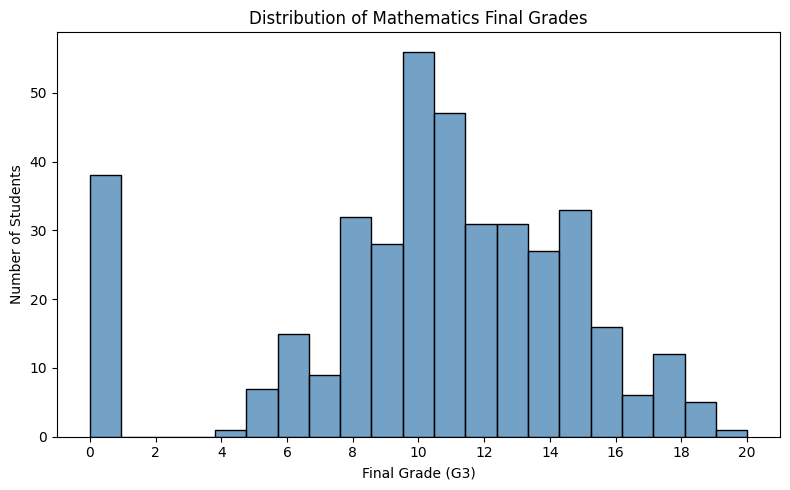

In [178]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["G3"],
    bins=21,
    kde=False,
    color="steelblue"
)

plt.title("Distribution of Mathematics Final Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")

plt.xticks(range(0, 21, 2))
plt.tight_layout()

# Save graph and display it
save_plot("07_G3_grade_distribution.png")

Relationship between G1, G2 and G3

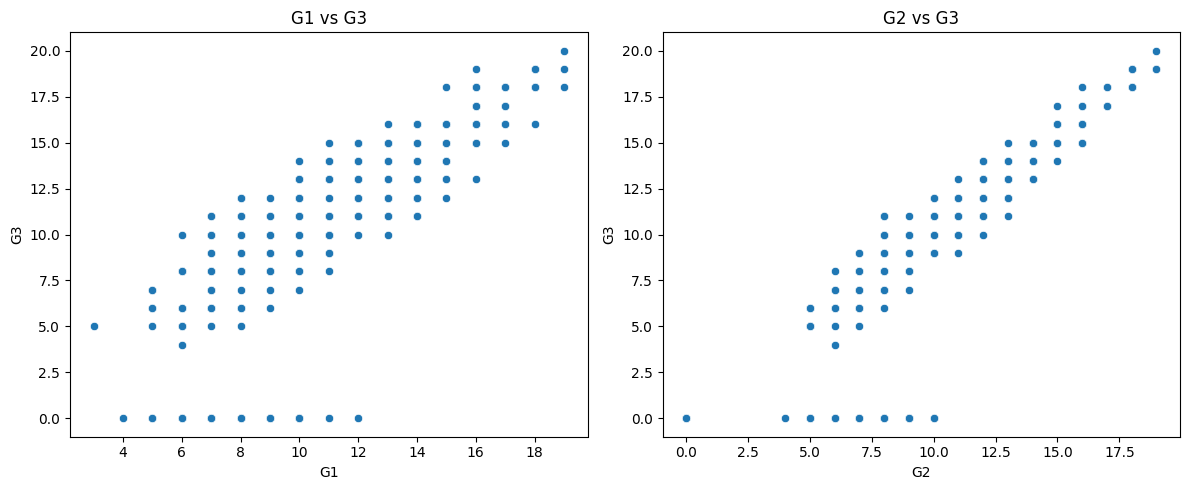

In [179]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(data=df, x="G1", y="G3", ax=axes[0])
axes[0].set_title("G1 vs G3")

sns.scatterplot(data=df, x="G2", y="G3", ax=axes[1])
axes[1].set_title("G2 vs G3")

plt.tight_layout()

save_plot("G1_G2_vs_G3_scatter.png")

Study time vs G3

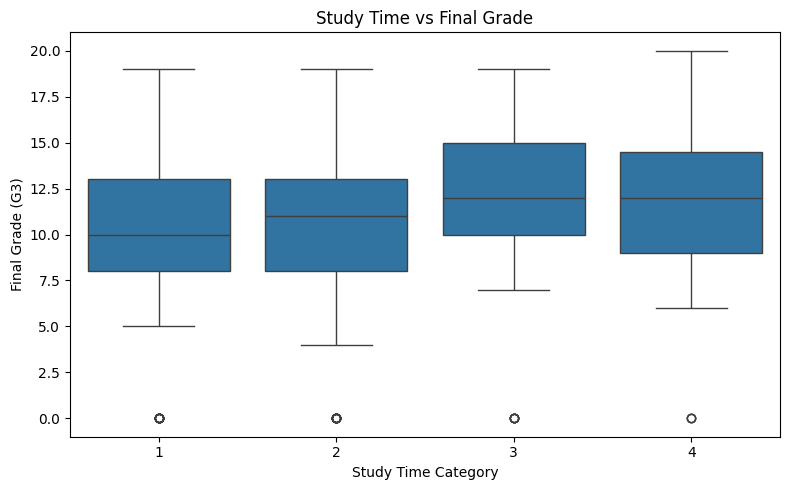

In [180]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="studytime", y="G3")

plt.title("Study Time vs Final Grade")
plt.xlabel("Study Time Category")
plt.ylabel("Final Grade (G3)")

plt.tight_layout()

save_plot("Study_Time_vs_Final_Grade.png")

Correlation heatmap

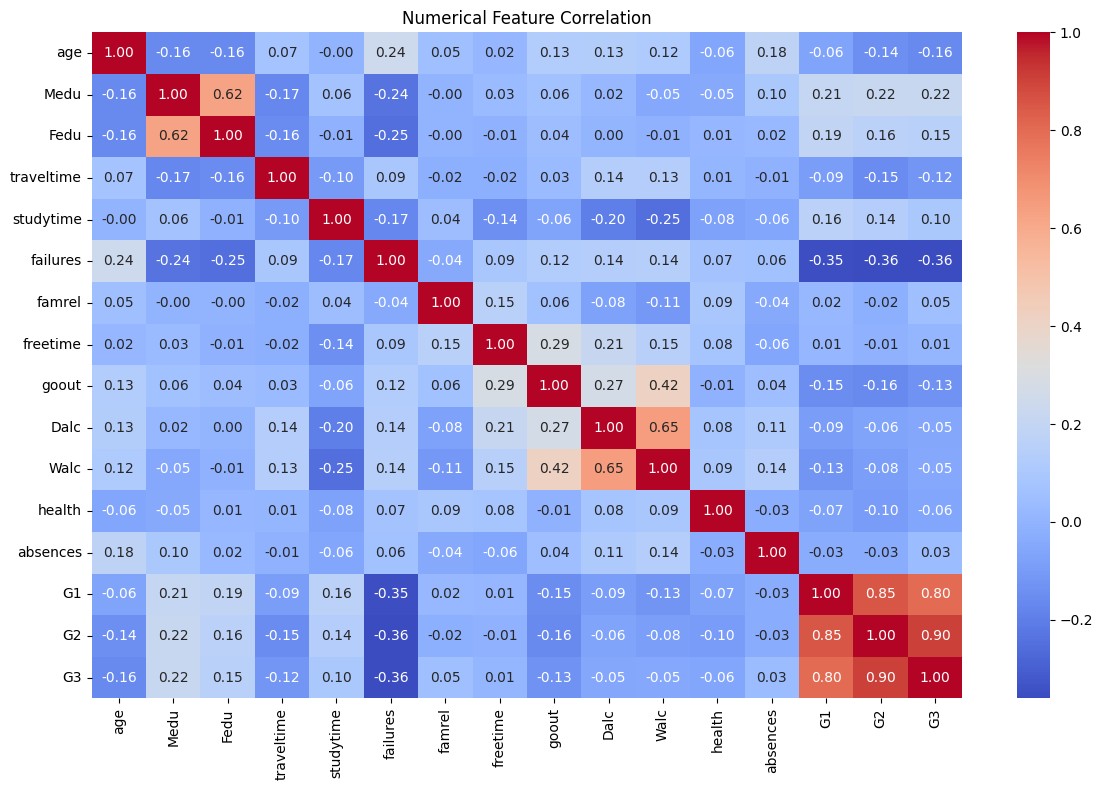

In [181]:
plt.figure(figsize=(12, 8))

numeric_df = df.select_dtypes(include="number")

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Numerical Feature Correlation")

plt.tight_layout()

save_plot("Numerical_Feature_Correlation.png")

Separate features (X) and target (y)

In [182]:
X = df.drop(columns=["G3"])
y = df["G3"]

print("Input features:", X.shape)
print("Target:", y.shape)

print("\nInput columns:")
print(X.columns.tolist())

Input features: (395, 32)
Target: (395,)

Input columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']


Split training and testing data

In [183]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (316, 32)
X_test: (79, 32)
y_train: (316,)
y_test: (79,)


Identify numerical and categorical columns

In [184]:
numerical_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", numerical_cols)
print("\nCategorical features:", categorical_cols)

print("\nNumerical count:", len(numerical_cols))
print("Categorical count:", len(categorical_cols))

Numerical features: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']

Categorical features: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Numerical count: 15
Categorical count: 17


Create numerical preprocessing pipeline

In [185]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

print("Numerical pipeline created successfully!")

Numerical pipeline created successfully!


Visualize numerical features before scaling

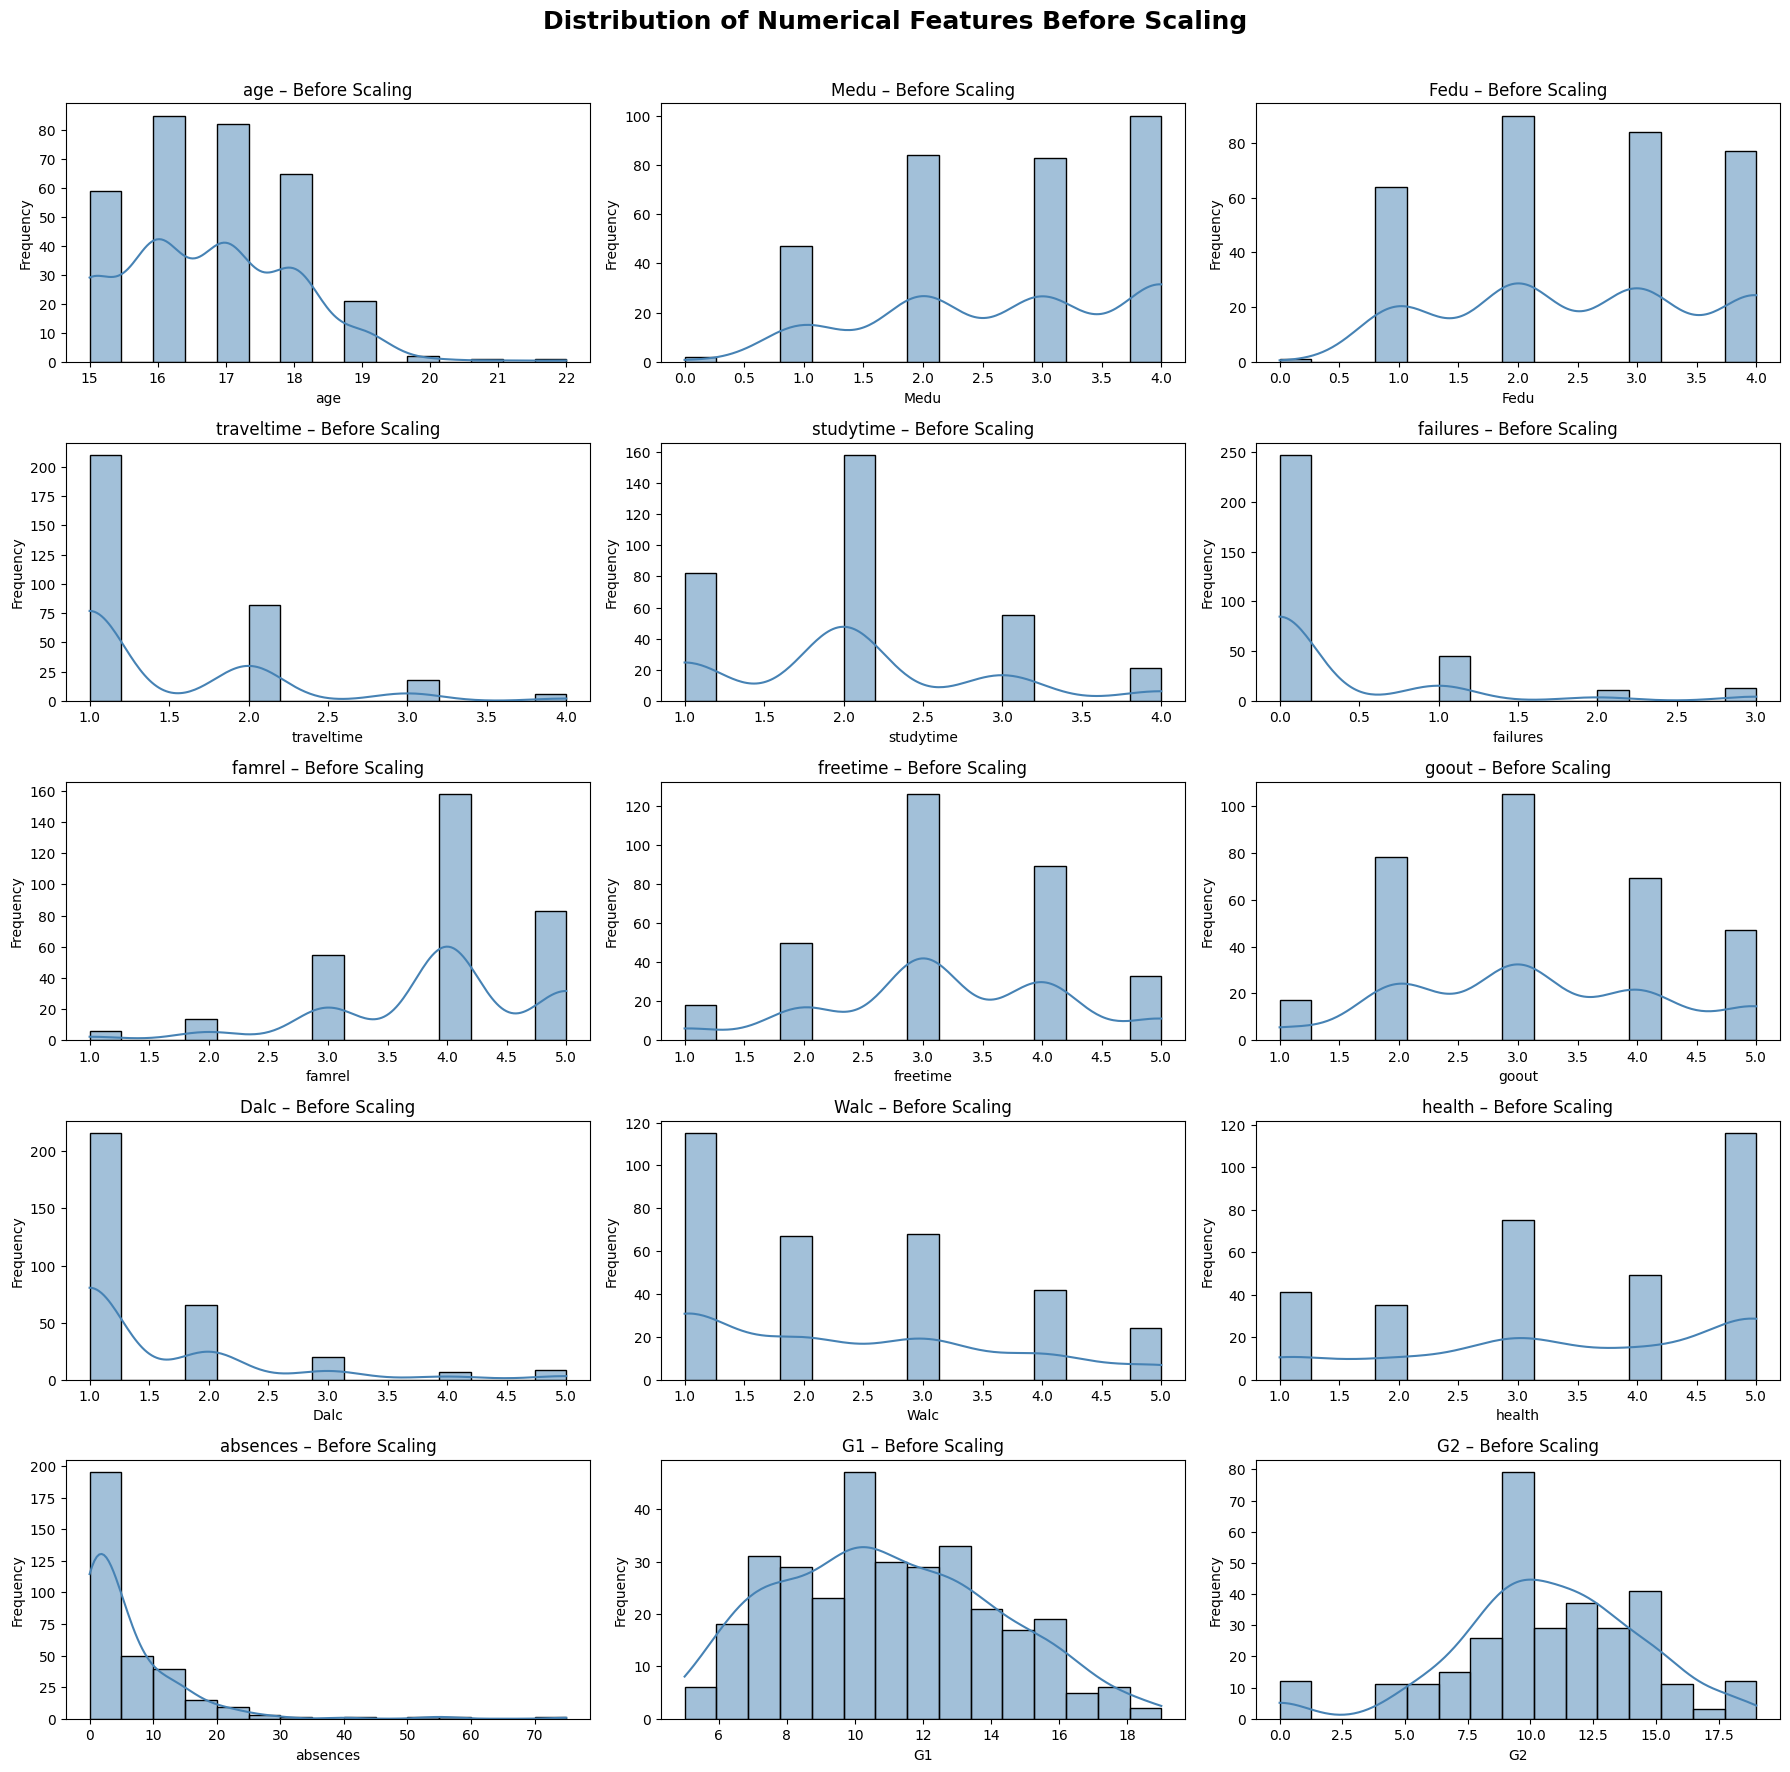

In [186]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

n_cols = 3
n_rows = math.ceil(len(numerical_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, n_rows * 3.5)
)

axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.histplot(
        X_train[col],
        bins=15,
        kde=True,
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(f"{col} – Before Scaling")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

for j in range(len(numerical_cols), len(axes)):
    axes[j].axis("off")

plt.suptitle(
    "Distribution of Numerical Features Before Scaling",
    fontsize=18,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()

save_plot("Numerical_Features_Before_Scaling.png")

Fit numerical preprocessing on training data

In [187]:
X_num_scaled = numerical_pipeline.fit_transform(
    X_train[numerical_cols]
)

X_num_scaled_df = pd.DataFrame(
    X_num_scaled,
    columns=numerical_cols,
    index=X_train.index
)

display(X_num_scaled_df.head())

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2
181,-0.5,0.0,0.0,0.0,0.0,0.0,0.0,-1.0,0.0,0.0,0.0,-0.5,-0.25,0.2,0.50
194,-0.5,-0.5,0.0,1.0,-1.0,0.0,1.0,0.0,0.0,0.0,-0.5,-0.5,-0.50,0.4,0.75
173,-0.5,-1.0,0.0,0.0,0.0,3.0,0.0,0.0,1.0,0.0,-0.5,-0.5,-0.50,-0.6,-1.00
63,-0.5,0.5,0.0,0.0,1.0,0.0,-1.0,1.0,0.5,1.0,1.0,0.0,-0.25,-0.2,-0.50
253,-0.5,-0.5,-2.0,1.0,-1.0,0.0,-1.0,0.0,-0.5,0.0,0.5,-0.5,-0.50,-0.6,-0.50


Visualize before and after scaling

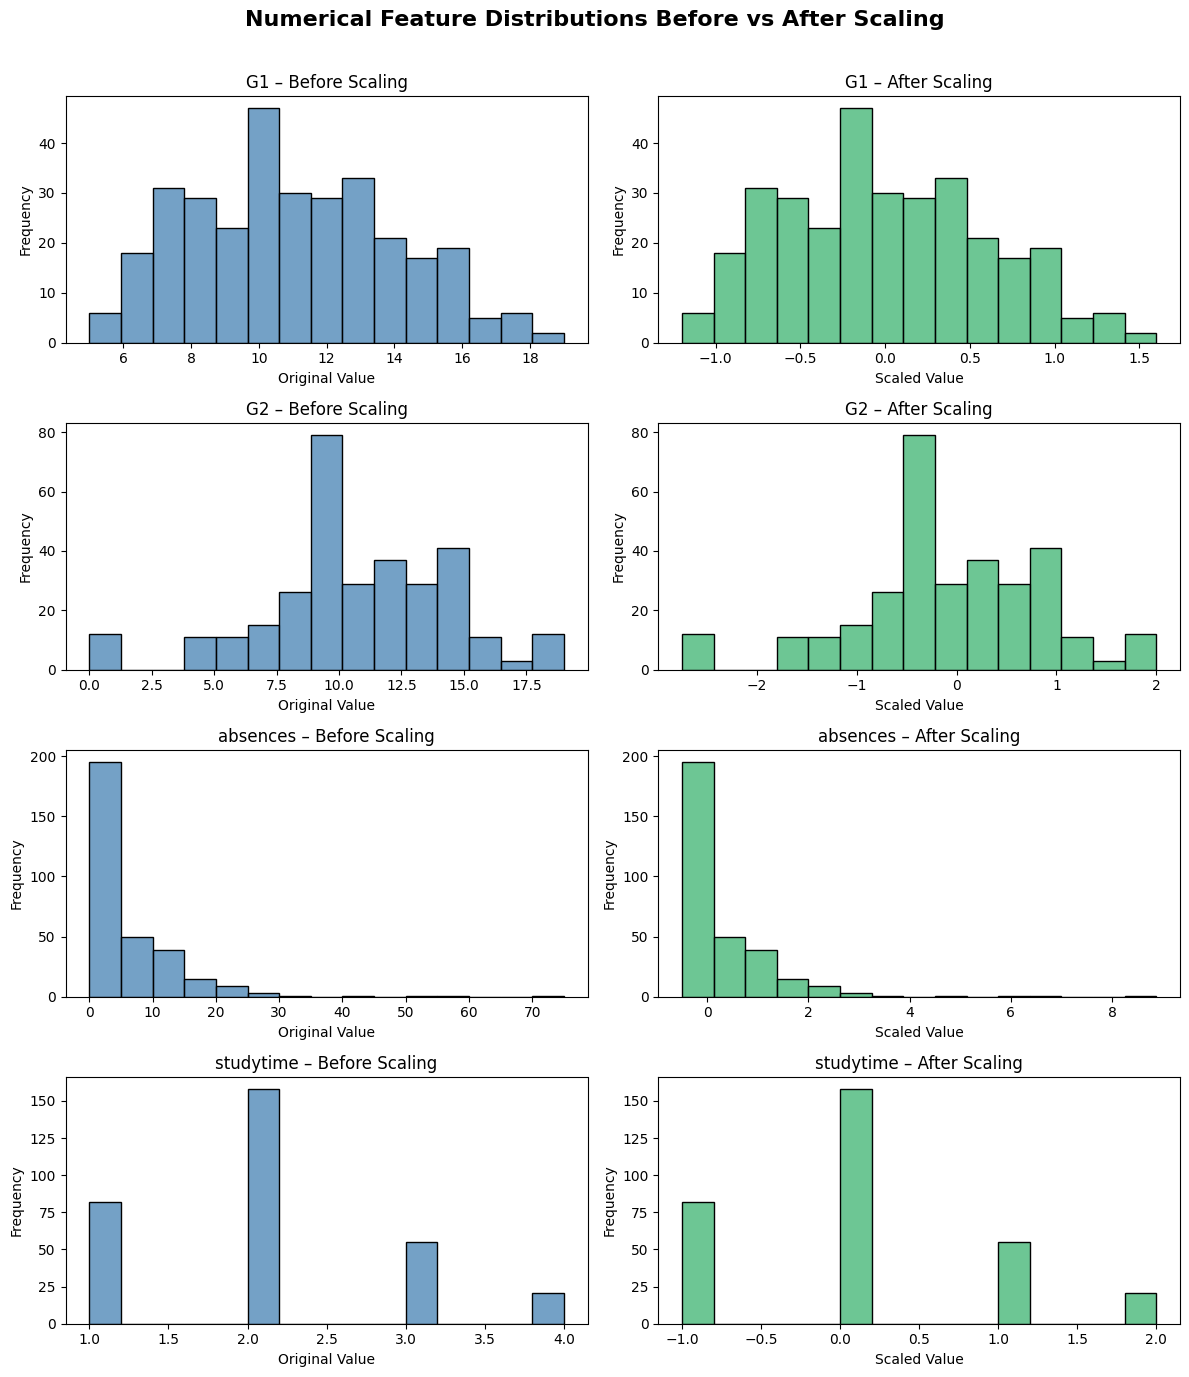

In [188]:
features_to_compare = ["G1", "G2", "absences", "studytime"]

fig, axes = plt.subplots(
    len(features_to_compare), 2,
    figsize=(12, 14)
)

for i, col in enumerate(features_to_compare):

    # Before Scaling
    sns.histplot(
        X_train[col],
        bins=15,
        ax=axes[i, 0],
        color="steelblue"
    )

    axes[i, 0].set_title(f"{col} – Before Scaling")
    axes[i, 0].set_xlabel("Original Value")
    axes[i, 0].set_ylabel("Frequency")

    # After Scaling
    sns.histplot(
        X_num_scaled_df[col],
        bins=15,
        ax=axes[i, 1],
        color="mediumseagreen"
    )

    axes[i, 1].set_title(f"{col} – After Scaling")
    axes[i, 1].set_xlabel("Scaled Value")
    axes[i, 1].set_ylabel("Frequency")

plt.suptitle(
    "Numerical Feature Distributions Before vs After Scaling",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.97])

save_plot("Numerical_Features_Before_After_Scaling.png")

Visualize numerical features using box plots

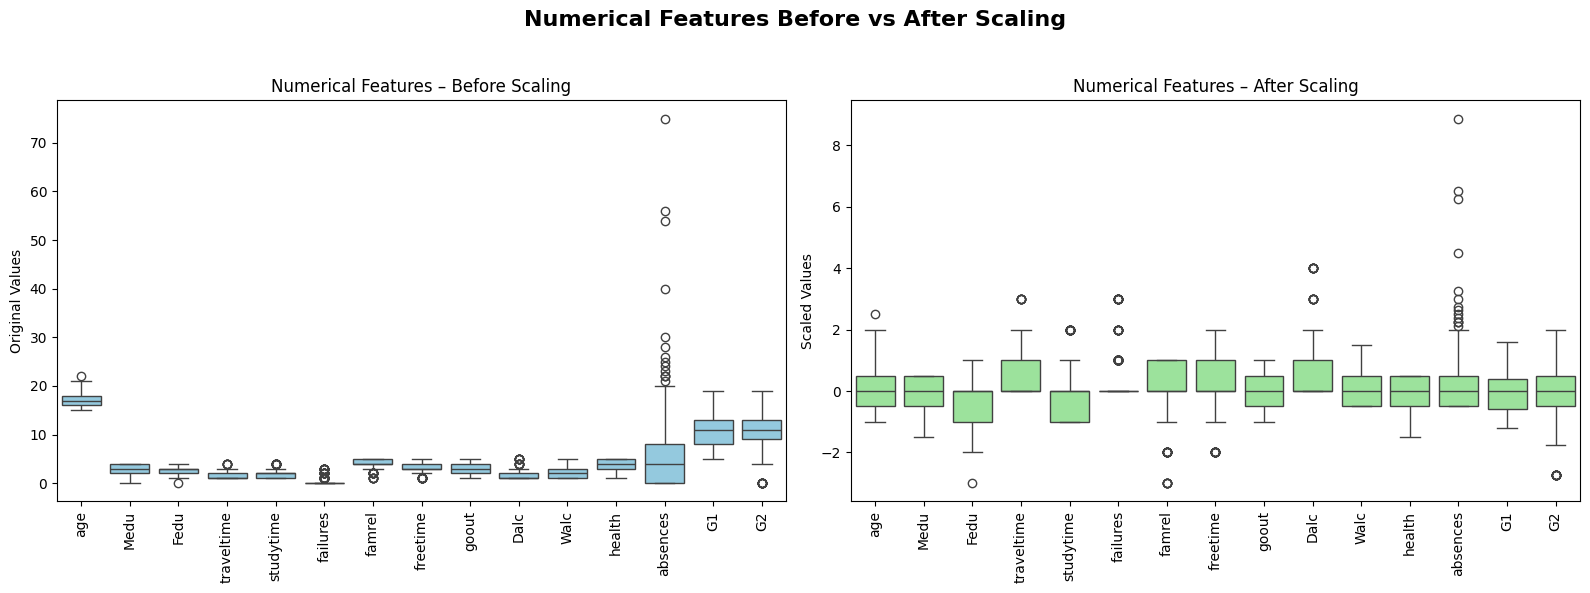

In [189]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Before Scaling
sns.boxplot(
    data=X_train[numerical_cols],
    ax=axes[0],
    color="skyblue"
)

axes[0].set_title("Numerical Features – Before Scaling")
axes[0].set_ylabel("Original Values")
axes[0].tick_params(axis="x", rotation=90)

# After Scaling
sns.boxplot(
    data=X_num_scaled_df[numerical_cols],
    ax=axes[1],
    color="lightgreen"
)

axes[1].set_title("Numerical Features – After Scaling")
axes[1].set_ylabel("Scaled Values")
axes[1].tick_params(axis="x", rotation=90)

plt.suptitle(
    "Numerical Features Before vs After Scaling",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

save_plot("Numerical_Features_Boxplot_Before_After_Scaling.png")

Categorical preprocessing

Create categorical pipeline

In [190]:
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

Visualize categorical distributions

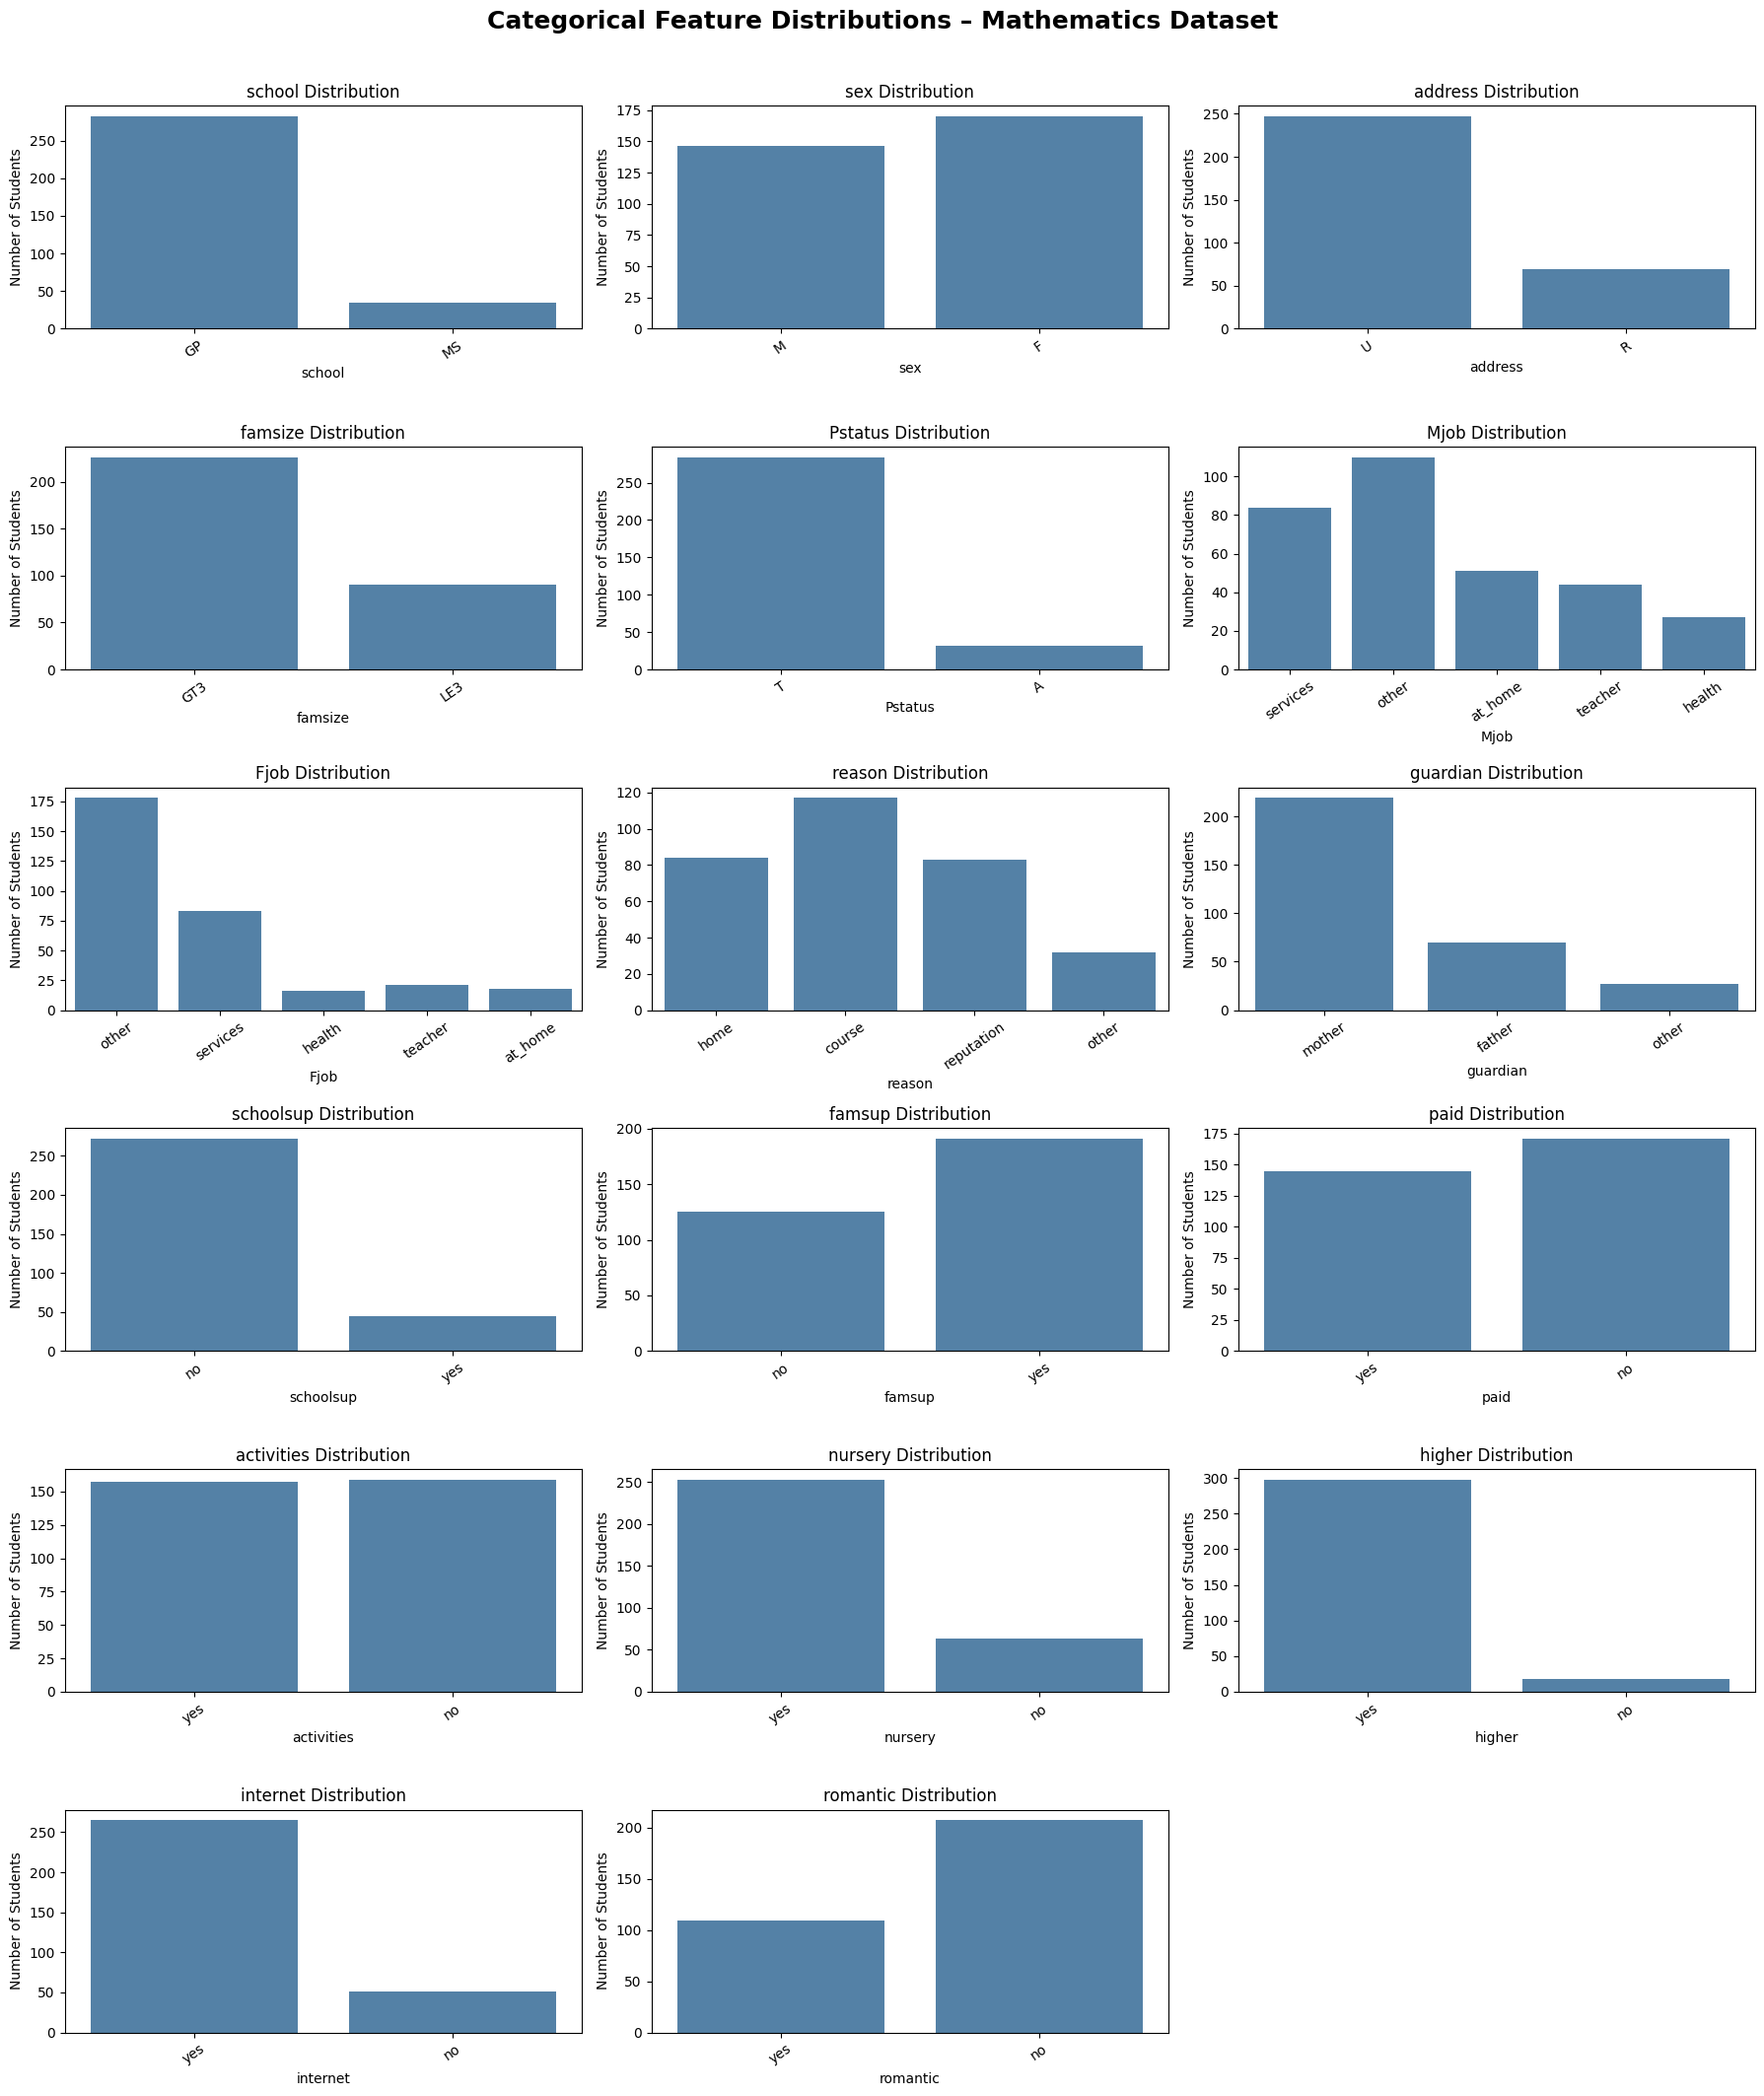

In [191]:
n_cols = 3
n_rows = math.ceil(len(categorical_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, n_rows * 3.5)
)

axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    sns.countplot(
        data=X_train,
        x=col,
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(f"{col} Distribution")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Number of Students")
    axes[i].tick_params(axis="x", rotation=35)

for j in range(len(categorical_cols), len(axes)):
    axes[j].axis("off")

plt.suptitle(
    "Categorical Feature Distributions – Mathematics Dataset",
    fontsize=18,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()

save_plot("Categorical_Feature_Distributions.png")

Visualize categorical features vs G3

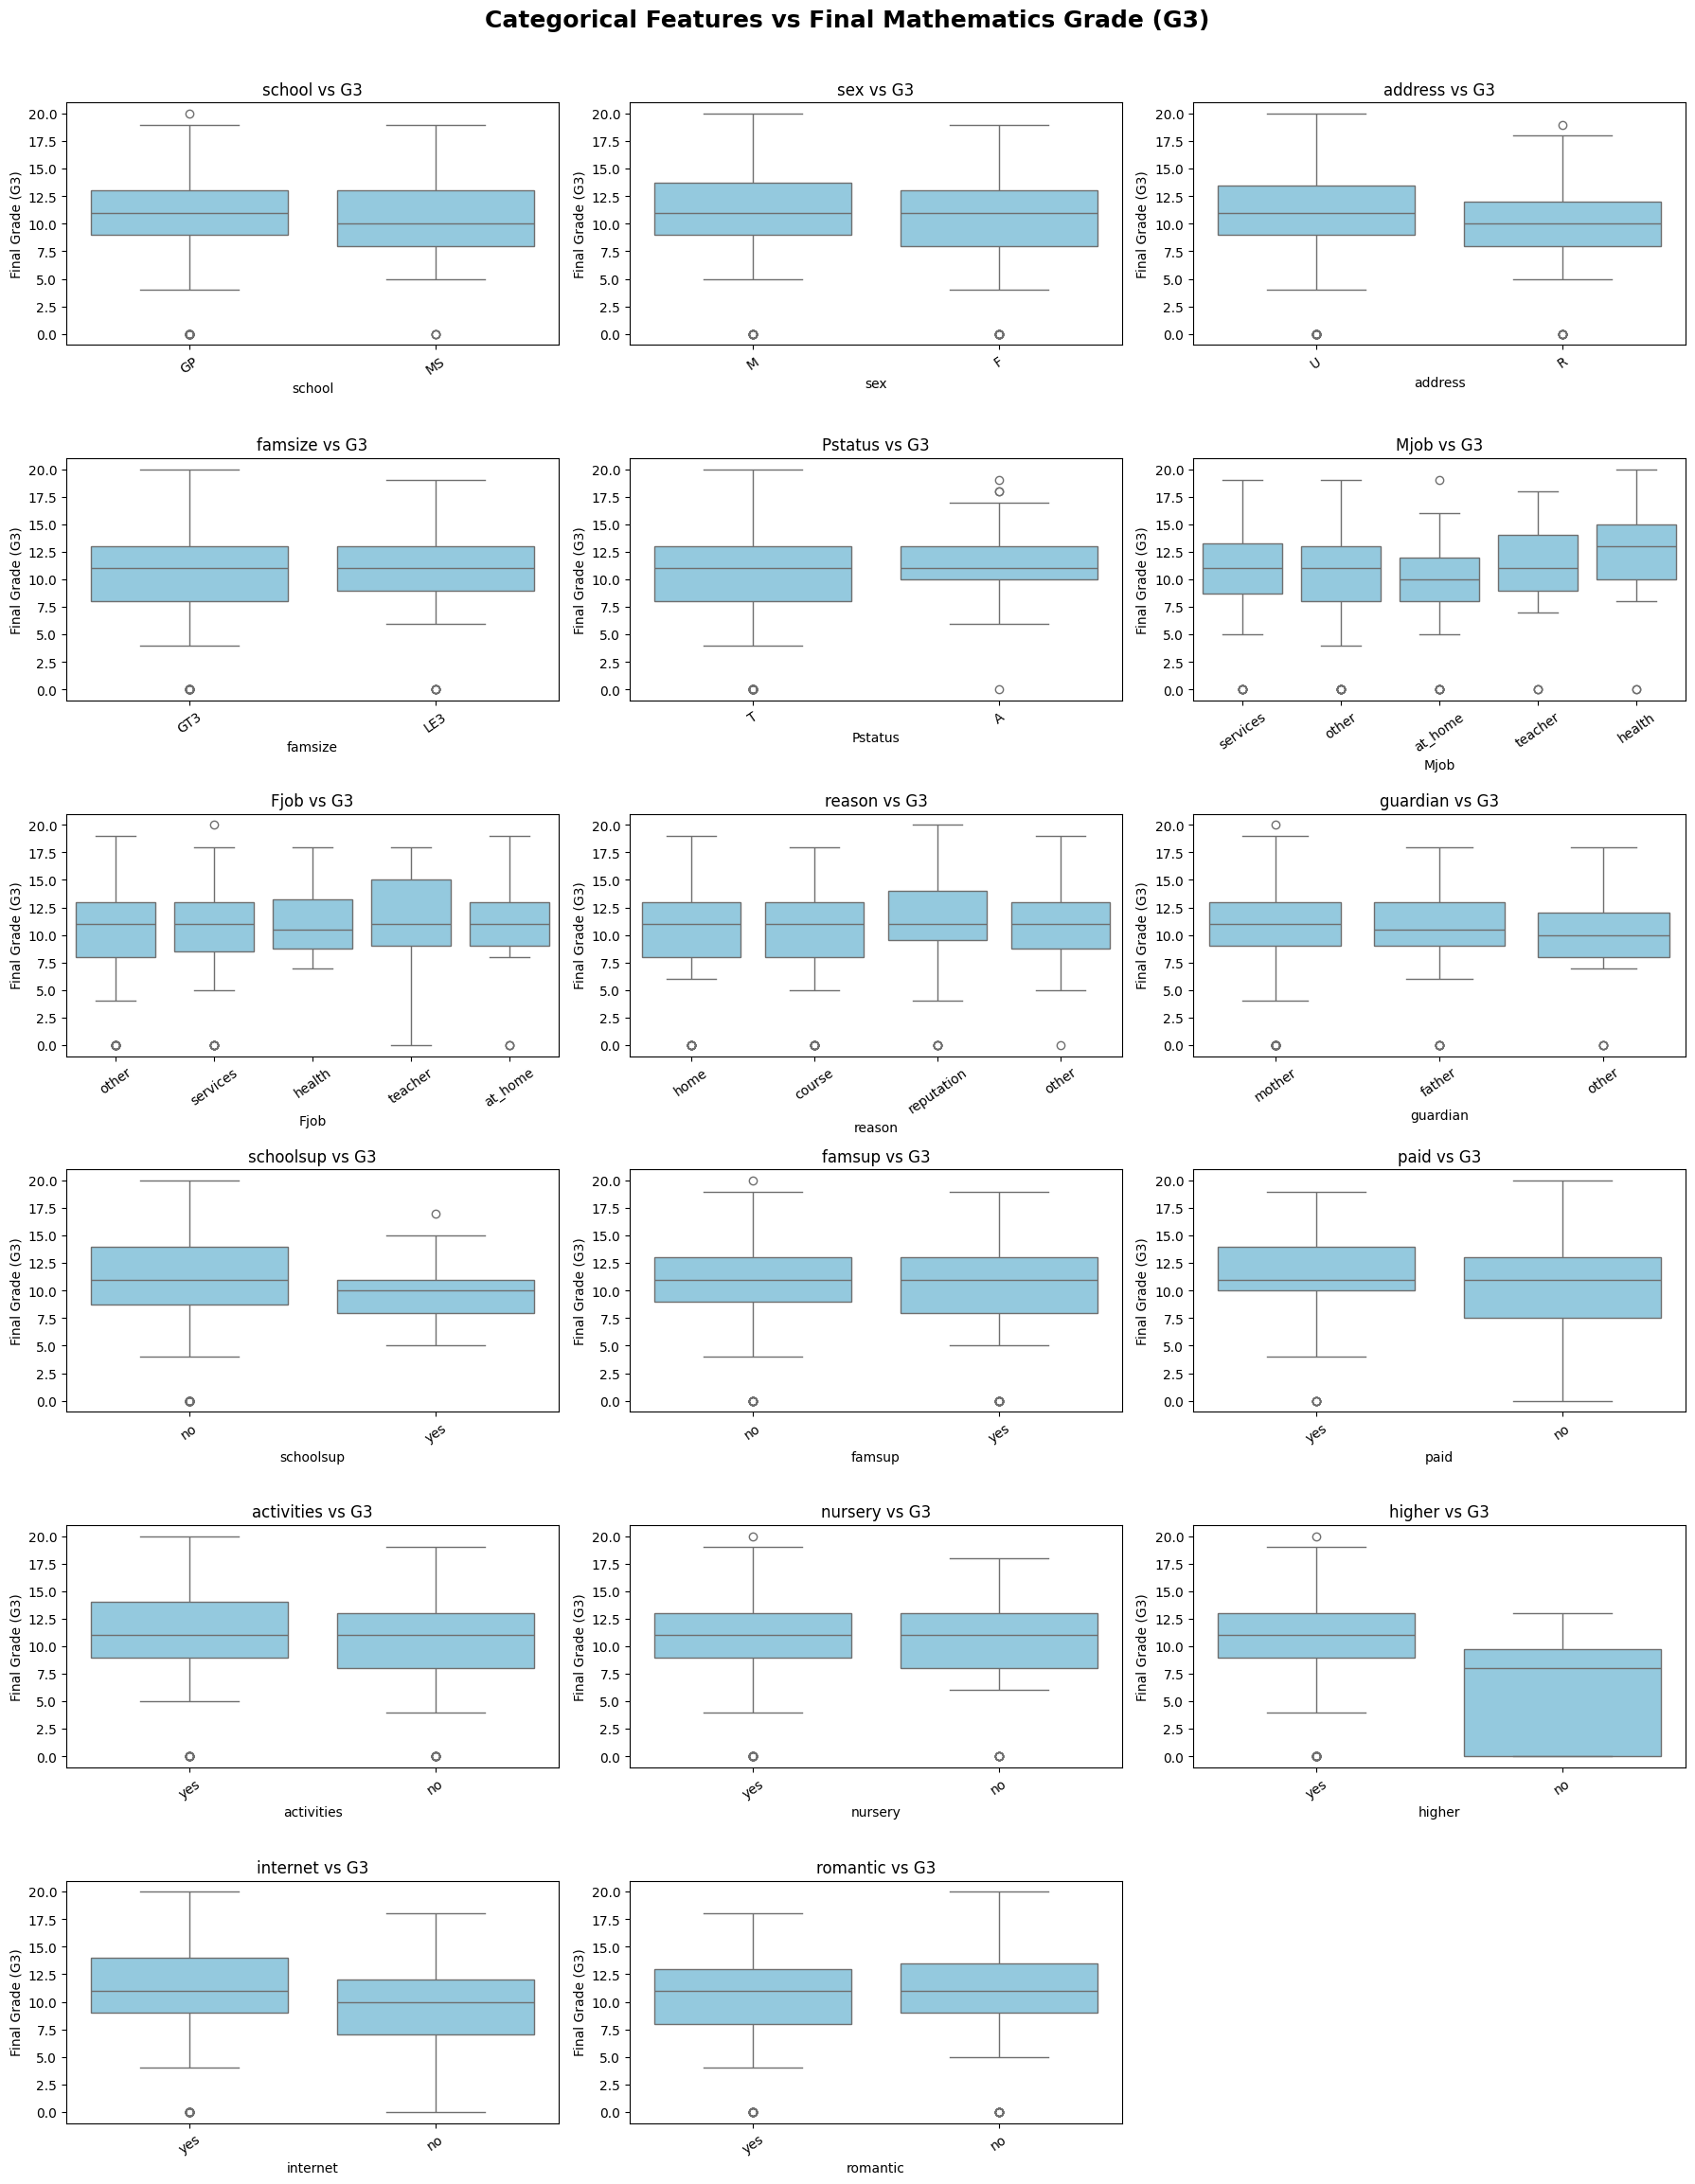

In [192]:
train_data = X_train.copy()
train_data["G3"] = y_train

n_cols = 3
n_rows = math.ceil(len(categorical_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, n_rows * 3.8)
)

axes = axes.flatten()

for i, col in enumerate(categorical_cols):

    sns.boxplot(
        data=train_data,
        x=col,
        y="G3",
        ax=axes[i],
        color="skyblue"
    )

    axes[i].set_title(f"{col} vs G3")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Final Grade (G3)")
    axes[i].tick_params(axis="x", rotation=35)

for j in range(len(categorical_cols), len(axes)):
    axes[j].axis("off")

plt.suptitle(
    "Categorical Features vs Final Mathematics Grade (G3)",
    fontsize=18,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()

save_plot("Categorical_Features_vs_Final_Grade_G3.png")

Fit and visualize One-Hot Encoding

In [193]:
X_cat_encoded = categorical_pipeline.fit_transform(
    X_train[categorical_cols]
)

encoder = categorical_pipeline.named_steps["encoder"]

encoded_columns = encoder.get_feature_names_out(
    categorical_cols
)

X_cat_df = pd.DataFrame(
    X_cat_encoded.toarray()
    if hasattr(X_cat_encoded, "toarray")
    else X_cat_encoded,
    columns=encoded_columns,
    index=X_train.index
)

print("Before encoding:")
display(X_train[categorical_cols].head())

print("After encoding:")
display(X_cat_df.head())

Before encoding:


,school,sex,address,famsize,Pstatus,Mjob,Fjob,reason,guardian,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic
181,GP,M,U,GT3,T,services,other,home,mother,no,no,yes,yes,yes,yes,yes,yes
194,GP,M,U,GT3,T,other,other,home,father,no,no,no,no,yes,yes,yes,no
173,GP,F,U,GT3,T,at_home,services,home,mother,no,no,no,yes,no,yes,yes,yes
63,GP,F,U,GT3,T,teacher,health,home,mother,yes,yes,yes,yes,yes,yes,yes,no
253,GP,M,R,GT3,T,other,other,course,mother,no,no,no,yes,no,yes,no,no


After encoding:


,school_GP,school_MS,sex_F,sex_M,address_R,address_U,famsize_GT3,famsize_LE3,Pstatus_A,Pstatus_T,...,activities_no,activities_yes,nursery_no,nursery_yes,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes
181,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0
194,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0
173,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,...,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
63,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0
253,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,...,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0


One-Hot Encoding heatmap

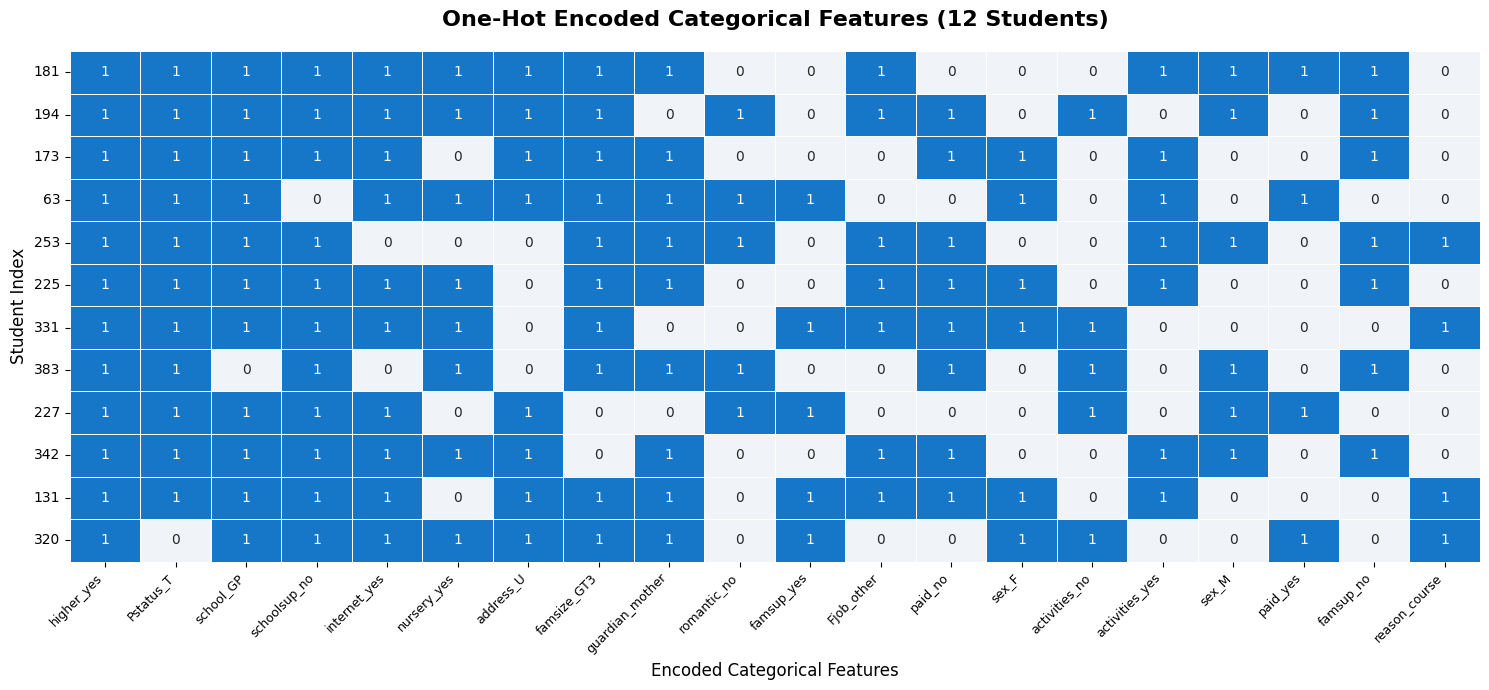

In [194]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

output_dir = Path(r"C:\Users\U S E R\Desktop\ML Assigment\project\output")
output_dir.mkdir(parents=True, exist_ok=True)

# Select the most frequently active encoded columns
top_columns = X_cat_df.sum().sort_values(
    ascending=False
).head(20).index

heatmap_data = X_cat_df[top_columns].head(12)

plt.figure(figsize=(15, 7))

sns.heatmap(
    heatmap_data,
    cmap=sns.color_palette(["#F0F4F8", "#1677C8"]),
    linewidths=0.6,
    linecolor="white",
    cbar=False,
    annot=True,
    fmt=".0f"
)

plt.title(
    "One-Hot Encoded Categorical Features (12 Students)",
    fontsize=16,
    fontweight="bold",
    pad=18
)

plt.xlabel("Encoded Categorical Features", fontsize=12)
plt.ylabel("Student Index", fontsize=12)

plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    output_dir / "step12_onehot_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Combine numerical and categorical pipelines

In [195]:
from sklearn.compose import ColumnTransformer

math_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_cols),
        ("cat", categorical_pipeline, categorical_cols)
    ]
)

print("Combined Mathematics preprocessing pipeline created!")

Combined Mathematics preprocessing pipeline created!


In [196]:
from sklearn import set_config

set_config(display="diagram")

display(math_preprocessor)

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


Fit and transform the training data

In [197]:
X_train_processed = math_preprocessor.fit_transform(X_train)

X_test_processed = math_preprocessor.transform(X_test)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("Original testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

Original training shape: (316, 32)
Processed training shape: (316, 58)
Original testing shape: (79, 32)
Processed testing shape: (79, 58)


Visualize feature count before and after

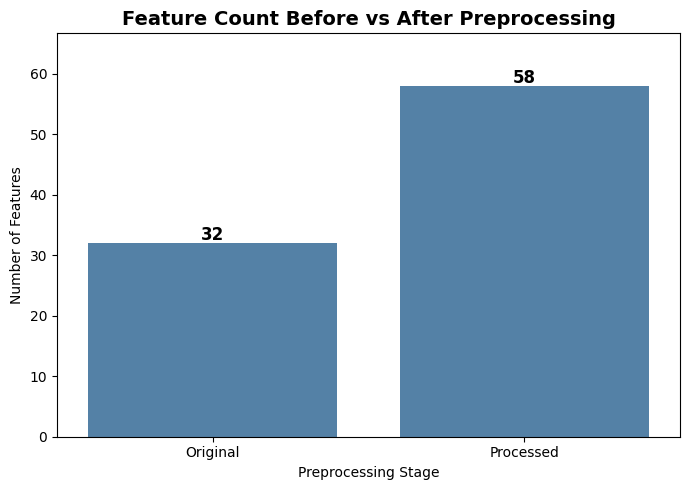

In [198]:
original_count = X_train.shape[1]
processed_count = X_train_processed.shape[1]

plt.figure(figsize=(7, 5))

sns.barplot(
    x=["Original", "Processed"],
    y=[original_count, processed_count],
    color="steelblue"
)

plt.title(
    "Feature Count Before vs After Preprocessing",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Preprocessing Stage")
plt.ylabel("Number of Features")

plt.ylim(0, max(original_count, processed_count) * 1.15)

for i, value in enumerate([original_count, processed_count]):
    plt.text(
        i,
        value + 0.5,
        str(value),
        ha="center",
        fontweight="bold",
        fontsize=12
    )

plt.tight_layout()

save_plot("Feature_Count_Before_After_Preprocessing.png")


Visualize the transformed feature matrix

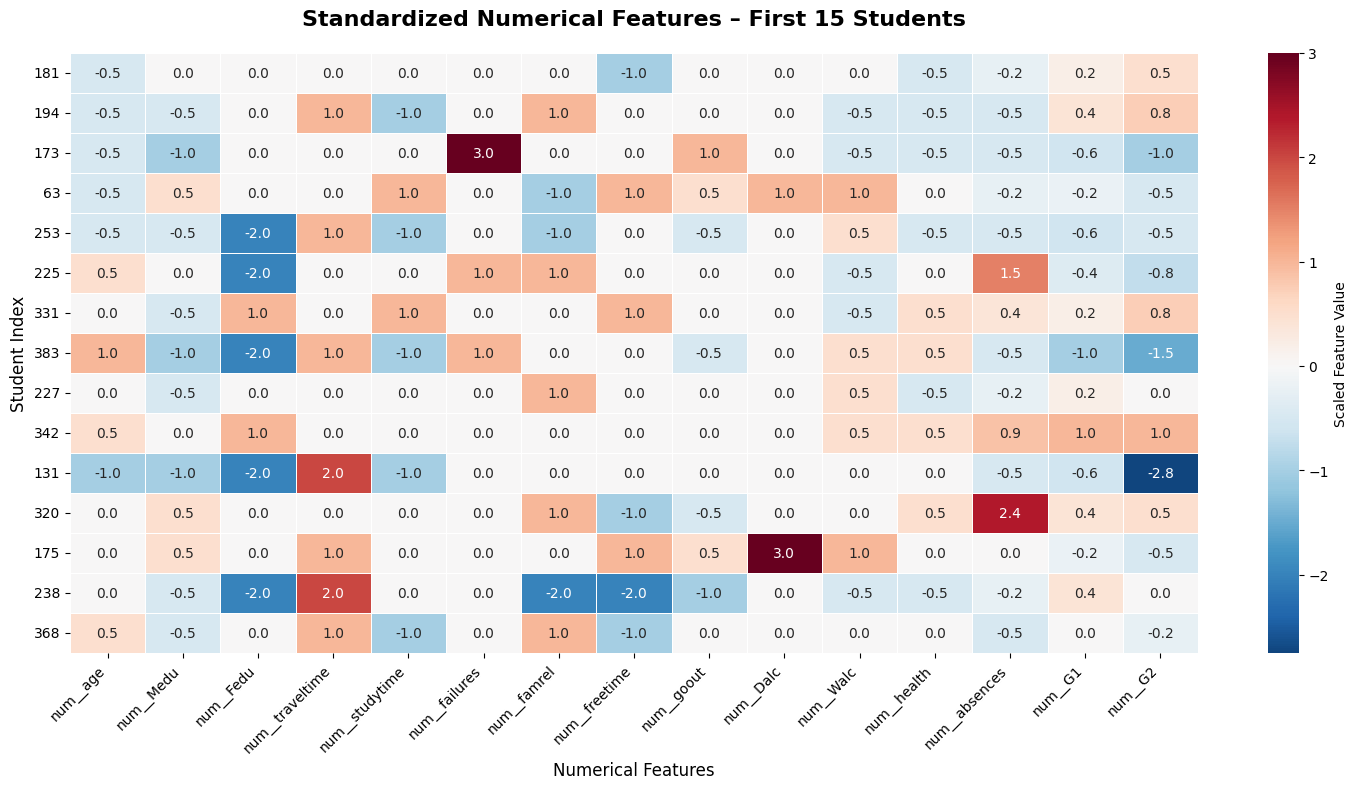

In [199]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from pathlib import Path

output_dir = Path(
    r"C:\Users\U S E R\Desktop\ML Assigment\project\output"
)

output_dir.mkdir(parents=True, exist_ok=True)

# Get processed feature names
feature_names = math_preprocessor.get_feature_names_out()

# Convert processed data into DataFrame
X_train_clean = pd.DataFrame(
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed,
    columns=feature_names,
    index=X_train.index
)

# Select numerical features from ColumnTransformer
numerical_feature_names = [
    col for col in X_train_clean.columns
    if col.startswith("num__")
]

# Select first 15 students
heatmap_data = X_train_clean[
    numerical_feature_names
].head(15)

plt.figure(figsize=(15, 8))

sns.heatmap(
    heatmap_data,
    cmap="RdBu_r",
    center=0,
    annot=True,
    fmt=".1f",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Scaled Feature Value"}
)

plt.title(
    "Standardized Numerical Features – First 15 Students",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel("Numerical Features", fontsize=12)
plt.ylabel("Student Index", fontsize=12)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    output_dir / "step13_numerical_preprocessing_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Skewness Analysis and Transformation

In [200]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

skewness_df = pd.DataFrame({
    "Feature": numerical_cols,
    "Skewness": X_train[numerical_cols].skew().values
})

skewness_df["Absolute Skewness"] = skewness_df["Skewness"].abs()

skewness_df = skewness_df.sort_values(
    "Absolute Skewness",
    ascending=False
)

display(skewness_df.round(3))

,Feature,Skewness,Absolute Skewness
12,absences,3.680,3.680
5,failures,2.412,2.412
9,Dalc,2.172,2.172
3,traveltime,1.660,1.660
6,famrel,-0.938,0.938
4,studytime,0.599,0.599
10,Walc,0.552,0.552
14,G2,-0.521,0.521
0,age,0.491,0.491
11,health,-0.462,0.462


Visualize skewness

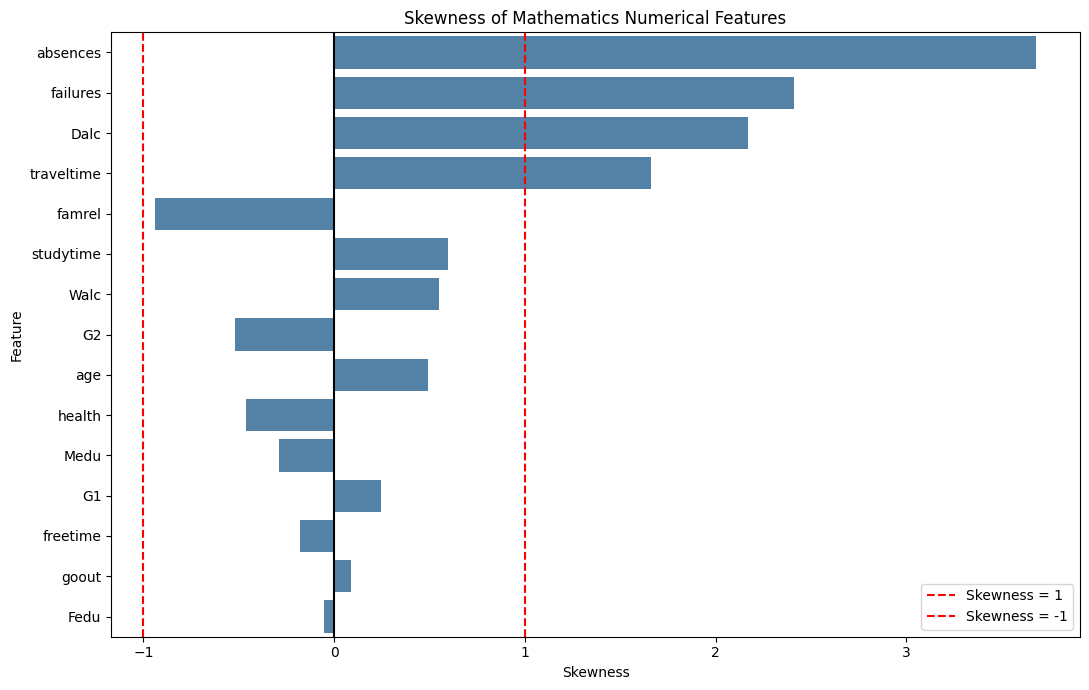

In [201]:
plt.figure(figsize=(11, 7))

sns.barplot(
    data=skewness_df,
    x="Skewness",
    y="Feature",
    color="steelblue"
)

plt.axvline(0, color="black")
plt.axvline(1, color="red", linestyle="--", label="Skewness = 1")
plt.axvline(-1, color="red", linestyle="--", label="Skewness = -1")

plt.title("Skewness of Mathematics Numerical Features")
plt.xlabel("Skewness")
plt.ylabel("Feature")
plt.legend()

plt.tight_layout()
save_plot("18_numerical_skewness.png")

Compare original and log-transformed absences

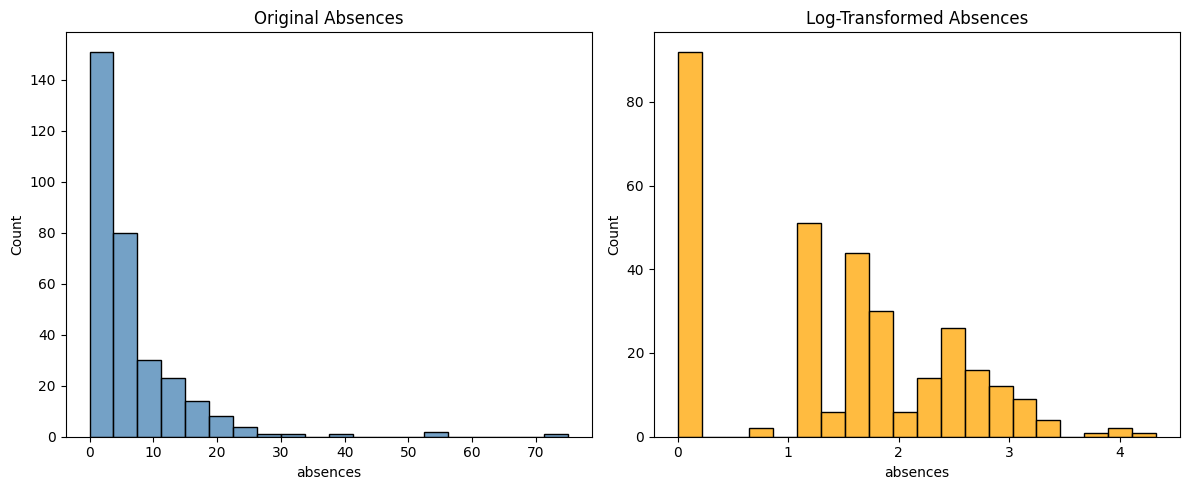

Original skewness: 3.6798
Transformed skewness: 0.0881


In [202]:
original = X_train["absences"]
transformed = np.log1p(original)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(original, bins=20, ax=axes[0], color="steelblue")
axes[0].set_title("Original Absences")

sns.histplot(transformed, bins=20, ax=axes[1], color="orange")
axes[1].set_title("Log-Transformed Absences")

plt.tight_layout()
save_plot("18_absences_before_after_log.png")

print("Original skewness:", round(original.skew(), 4))
print("Transformed skewness:", round(transformed.skew(), 4))

Compare prediction performance with and without transformation

In [203]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, cross_validate

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Baseline: your existing RobustScaler + OneHotEncoder
baseline_preprocessor = clone(math_preprocessor)

# Experiment: log-transform absences, then RobustScaler
log_absences_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scaler", RobustScaler())
])

other_numerical_cols = [
    col for col in numerical_cols if col != "absences"
]

transformation_preprocessor = ColumnTransformer([
    ("num", clone(numerical_pipeline), other_numerical_cols),
    ("absences_log", log_absences_pipeline, ["absences"]),
    ("cat", clone(categorical_pipeline), categorical_cols)
])

def evaluate_preprocessor(name, preprocessor):
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", Ridge(alpha=1.0))
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "MSE": "neg_mean_squared_error",
            "R2": "r2"
        }
    )

    return {
        "Experiment": name,
        "MAE": -scores["test_MAE"].mean(),
        "RMSE": np.sqrt(-scores["test_MSE"]).mean(),
        "R2": scores["test_R2"].mean()
    }

baseline_result = evaluate_preprocessor(
    "Baseline",
    baseline_preprocessor
)

transformation_result = evaluate_preprocessor(
    "Log Transformation",
    transformation_preprocessor
)

step18_results = pd.DataFrame([
    baseline_result,
    transformation_result
])

display(step18_results.round(4))

,Experiment,MAE,RMSE,R2
0,Baseline,1.3791,1.9756,0.8059
1,Log Transformation,1.3600,1.8721,0.8258


Visualize model performance

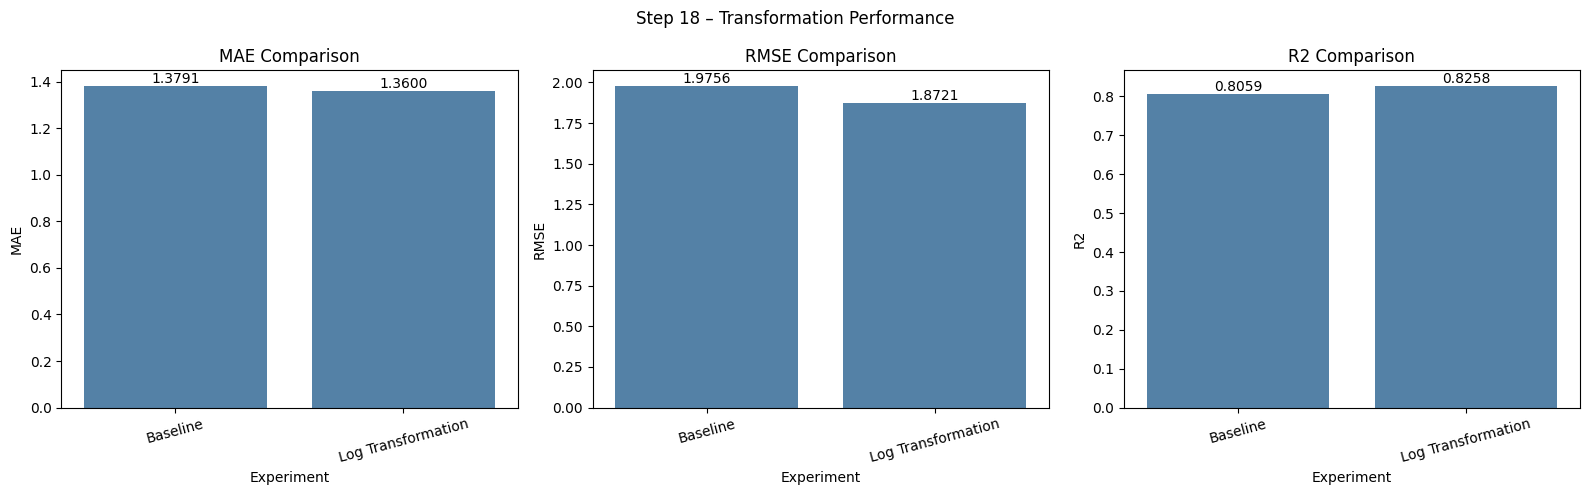

In [204]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric in zip(axes, ["MAE", "RMSE", "R2"]):

    sns.barplot(
        data=step18_results,
        x="Experiment",
        y=metric,
        color="steelblue",
        ax=ax
    )

    ax.set_title(f"{metric} Comparison")
    ax.tick_params(axis="x", rotation=15)

    for container in ax.containers:
        ax.bar_label(container, fmt="%.4f")

plt.suptitle("Step 18 – Transformation Performance")
plt.tight_layout()

save_plot("18_transformation_metrics.png")

step18_results.to_csv(
    processed_dir / "18_transformation_results.csv",
    index=False
)

Fit PCA for exploratory analysis

In [205]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Fit on training data only
numeric_scaled = clone(numerical_pipeline).fit_transform(
    X_train[numerical_cols]
)

# PCA requires centering around the mean.
# RobustScaler does not guarantee zero mean.
numeric_centered = StandardScaler(
    with_std=False
).fit_transform(numeric_scaled)

pca_analysis = PCA()
X_pca_analysis = pca_analysis.fit_transform(numeric_centered)

explained_variance = pca_analysis.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

n_components_95 = np.searchsorted(
    cumulative_variance,
    0.95
) + 1

print("Original numerical features:", numeric_scaled.shape[1])
print("Components for 95% variance:", n_components_95)
print("PCA output shape:", X_pca_analysis.shape)

Original numerical features: 15
Components for 95% variance: 12
PCA output shape: (316, 15)


Scree plot

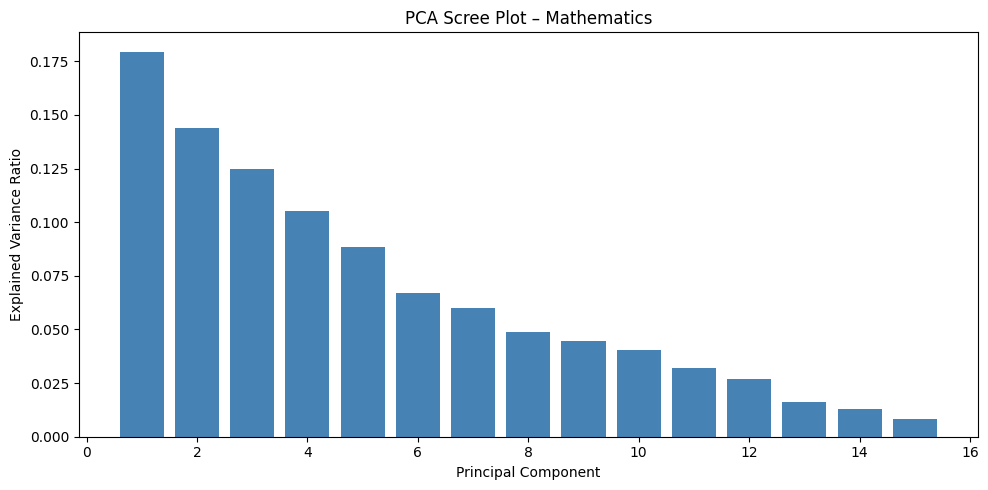

In [206]:
plt.figure(figsize=(10, 5))

plt.bar(
    range(1, len(explained_variance) + 1),
    explained_variance,
    color="steelblue"
)

plt.title("PCA Scree Plot – Mathematics")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")

plt.tight_layout()
save_plot("19_pca_scree_plot.png")

Cumulative explained variance

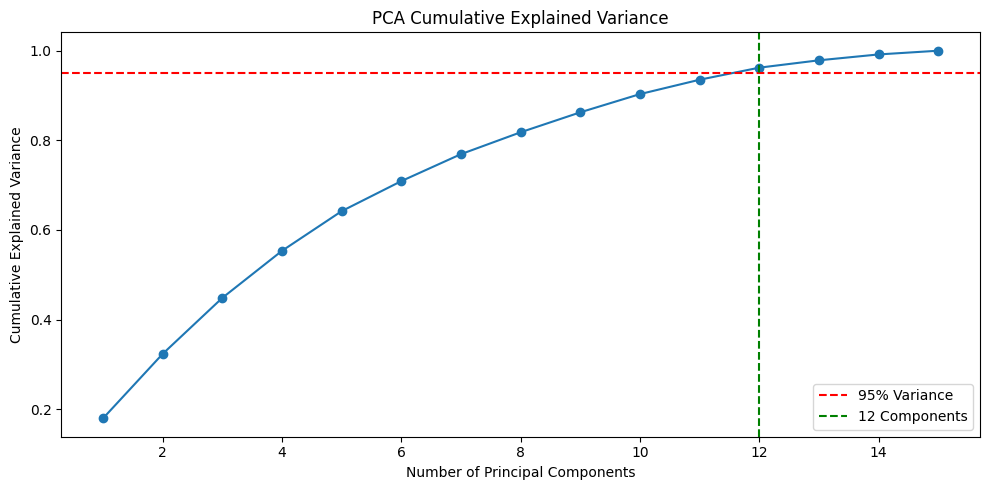

In [207]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    0.95,
    color="red",
    linestyle="--",
    label="95% Variance"
)

plt.axvline(
    n_components_95,
    color="green",
    linestyle="--",
    label=f"{n_components_95} Components"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Cumulative Explained Variance")

plt.legend()
plt.tight_layout()
save_plot("19_pca_cumulative_variance.png")

Compare before and after PCA

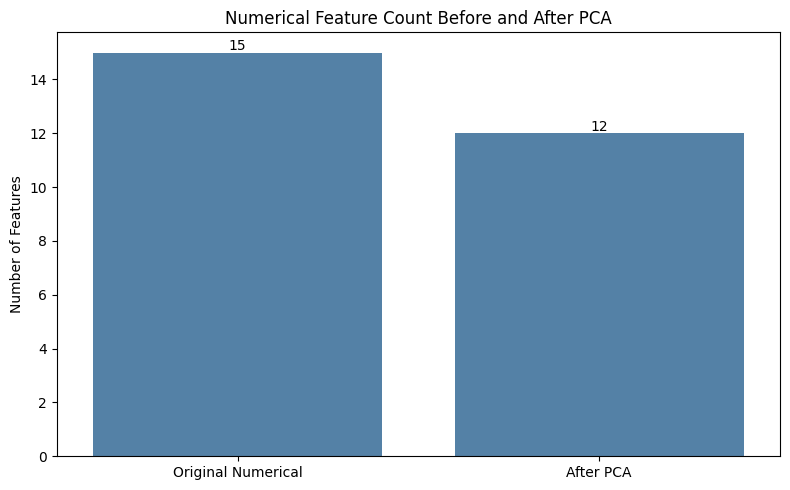

In [208]:
plt.figure(figsize=(8, 5))

counts = [
    len(numerical_cols),
    n_components_95
]

sns.barplot(
    x=["Original Numerical", "After PCA"],
    y=counts,
    color="steelblue"
)

for i, value in enumerate(counts):
    plt.text(i, value + 0.1, str(value), ha="center")

plt.title("Numerical Feature Count Before and After PCA")
plt.ylabel("Number of Features")

plt.tight_layout()
save_plot("19_pca_feature_count.png")

Compare prediction performance with and without PCA

In [209]:
pca_numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler()),
    ("pca", PCA(n_components=0.95))
])

pca_preprocessor = ColumnTransformer([
    ("num", pca_numerical_pipeline, numerical_cols),
    ("cat", clone(categorical_pipeline), categorical_cols)
])

pca_result = evaluate_preprocessor(
    "PCA",
    pca_preprocessor
)

step19_results = pd.DataFrame([
    baseline_result,
    pca_result
])

display(step19_results.round(4))

,Experiment,MAE,RMSE,R2
0,Baseline,1.3791,1.9756,0.8059
1,PCA,1.4194,1.9876,0.8032


Visualize PCA model performance

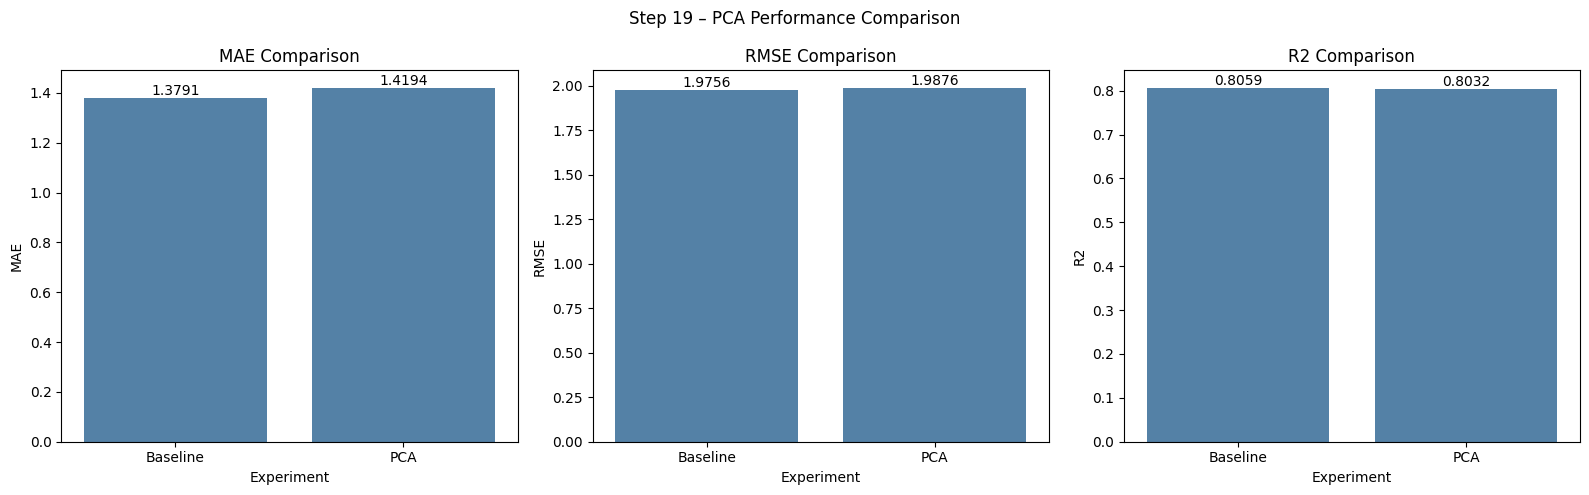

In [210]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric in zip(axes, ["MAE", "RMSE", "R2"]):

    sns.barplot(
        data=step19_results,
        x="Experiment",
        y=metric,
        color="steelblue",
        ax=ax
    )

    ax.set_title(f"{metric} Comparison")

    for container in ax.containers:
        ax.bar_label(container, fmt="%.4f")

plt.suptitle("Step 19 – PCA Performance Comparison")
plt.tight_layout()

save_plot("19_pca_model_metrics.png")

step19_results.to_csv(
    processed_dir / "19_pca_model_results.csv",
    index=False
)

Final preprocessing comparison

In [211]:
final_results = pd.DataFrame([
    baseline_result,
    transformation_result,
    pca_result
])

final_results = final_results.sort_values(
    "RMSE"
).reset_index(drop=True)

display(final_results.round(4))

,Experiment,MAE,RMSE,R2
0,Log Transformation,1.3600,1.8721,0.8258
1,Baseline,1.3791,1.9756,0.8059
2,PCA,1.4194,1.9876,0.8032


Visualize the final comparison

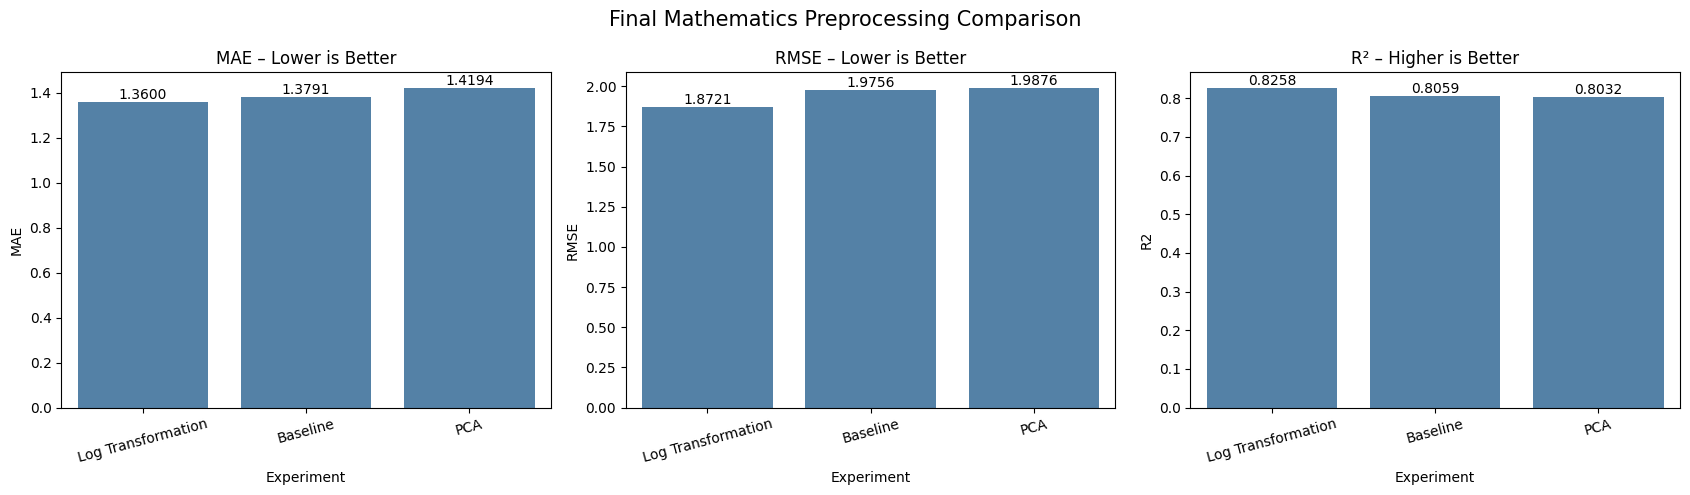

In [212]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

metrics = [
    ("MAE", "MAE – Lower is Better"),
    ("RMSE", "RMSE – Lower is Better"),
    ("R2", "R² – Higher is Better")
]

for ax, (metric, title) in zip(axes, metrics):

    sns.barplot(
        data=final_results,
        x="Experiment",
        y=metric,
        color="steelblue",
        ax=ax
    )

    ax.set_title(title)
    ax.tick_params(axis="x", rotation=15)

    for container in ax.containers:
        ax.bar_label(container, fmt="%.4f")

plt.suptitle(
    "Final Mathematics Preprocessing Comparison",
    fontsize=15
)

plt.tight_layout()
save_plot("20_final_preprocessing_comparison.png")

Select the best preprocessing configuration

In [213]:
best_experiment = final_results.iloc[0]

print("Best experiment:", best_experiment["Experiment"])
print("MAE:", round(best_experiment["MAE"], 4))
print("RMSE:", round(best_experiment["RMSE"], 4))
print("R²:", round(best_experiment["R2"], 4))

preprocessor_options = {
    "Baseline": baseline_preprocessor,
    "Log Transformation": transformation_preprocessor,
    "PCA": pca_preprocessor
}

selected_preprocessor = clone(
    preprocessor_options[best_experiment["Experiment"]]
)

final_results.to_csv(
    output_dir / "20_final_preprocessing_results.csv",
    index=False
)

print("Selected preprocessing configuration is ready.")

Best experiment: Log Transformation
MAE: 1.36
RMSE: 1.8721
R²: 0.8258
Selected preprocessing configuration is ready.


Compare Log Transformation with Log Transformation + PCA

Create the combined pipeline

In [214]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.base import clone
import numpy as np

# Numerical features excluding absences
other_numerical_cols = [
    col for col in numerical_cols
    if col != "absences"
]

# Transform absences separately
log_absences_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(
        np.log1p,
        feature_names_out="one-to-one"
    ))
])

# Combine numerical features, with absences transformed
numerical_transformer = ColumnTransformer([
    ("other_num", SimpleImputer(strategy="median"),
     other_numerical_cols),
    ("absences_log", log_absences_pipeline, ["absences"])
])

# Scale numerical features, then apply PCA
combined_numerical_pipeline = Pipeline([
    ("transform", numerical_transformer),
    ("scaler", RobustScaler()),
    ("pca", PCA(n_components=0.95))
])

# Preserve categorical encoding
combined_preprocessor = ColumnTransformer([
    ("num", combined_numerical_pipeline, numerical_cols),
    ("cat", clone(categorical_pipeline), categorical_cols)
])

print("Log Transformation + RobustScaler + PCA pipeline created.")

Log Transformation + RobustScaler + PCA pipeline created.


Evaluate the combined pipeline

In [215]:
combined_result = evaluate_preprocessor(
    "Log + PCA",
    combined_preprocessor
)

all_results = pd.DataFrame([
    baseline_result,
    transformation_result,
    pca_result,
    combined_result
])

all_results = all_results.sort_values(
    "RMSE"
).reset_index(drop=True)

display(all_results.round(4))

,Experiment,MAE,RMSE,R2
0,Log Transformation,1.3600,1.8721,0.8258
1,Log + PCA,1.3885,1.8898,0.8219
2,Baseline,1.3791,1.9756,0.8059
3,PCA,1.4194,1.9876,0.8032


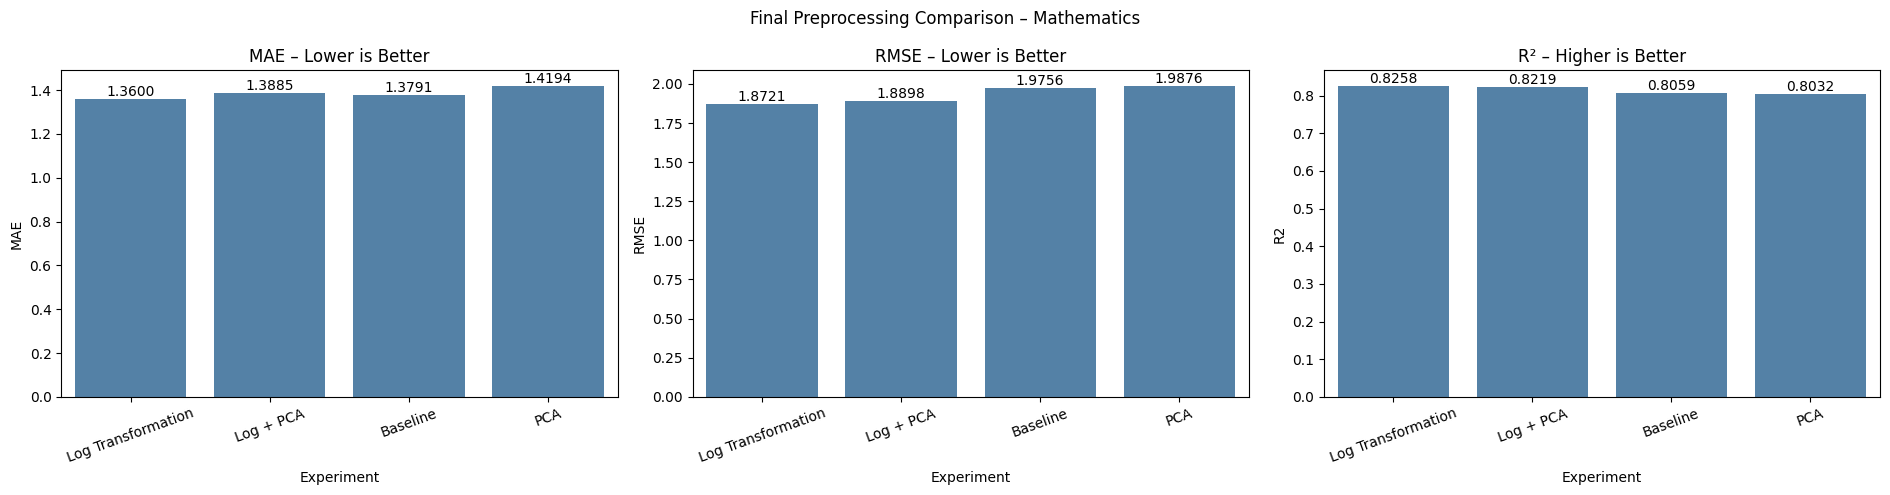

In [216]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

metrics = [
    ("MAE", "MAE – Lower is Better"),
    ("RMSE", "RMSE – Lower is Better"),
    ("R2", "R² – Higher is Better")
]

for ax, (metric, title) in zip(axes, metrics):
    sns.barplot(
        data=all_results,
        x="Experiment",
        y=metric,
        ax=ax,
        color="steelblue"
    )

    ax.set_title(title)
    ax.tick_params(axis="x", rotation=20)

    for container in ax.containers:
        ax.bar_label(container, fmt="%.4f")

plt.suptitle("Final Preprocessing Comparison – Mathematics")
plt.tight_layout()

save_plot("21_all_preprocessing_comparison.png")

In [217]:
preprocessor_options = {
    "Baseline": baseline_preprocessor,
    "Log Transformation": transformation_preprocessor,
    "PCA": pca_preprocessor,
    "Log + PCA": combined_preprocessor
}

winner = all_results.iloc[0]
winner_name = winner["Experiment"]

final_preprocessor = clone(
    preprocessor_options[winner_name]
)

print("=" * 45)
print("FINAL PREPROCESSING RESULT")
print("=" * 45)

print("Best configuration:", winner_name)
print(f"MAE:  {winner['MAE']:.4f}")
print(f"RMSE: {winner['RMSE']:.4f}")
print(f"R²:   {winner['R2']:.4f}")

all_results.to_csv(
    processed_dir / "21_all_preprocessing_results.csv",
    index=False
)

FINAL PREPROCESSING RESULT
Best configuration: Log Transformation
MAE:  1.3600
RMSE: 1.8721
R²:   0.8258


Compare all preprocessing results

In [218]:
final_results = pd.DataFrame([
    baseline_result,
    transformation_result,
    pca_result
])

final_results = final_results.sort_values(
    by=["RMSE", "MAE", "R2"],
    ascending=[True, True, False]
).reset_index(drop=True)

display(final_results.round(4))

,Experiment,MAE,RMSE,R2
0,Log Transformation,1.3600,1.8721,0.8258
1,Baseline,1.3791,1.9756,0.8059
2,PCA,1.4194,1.9876,0.8032


Visualize the final comparison

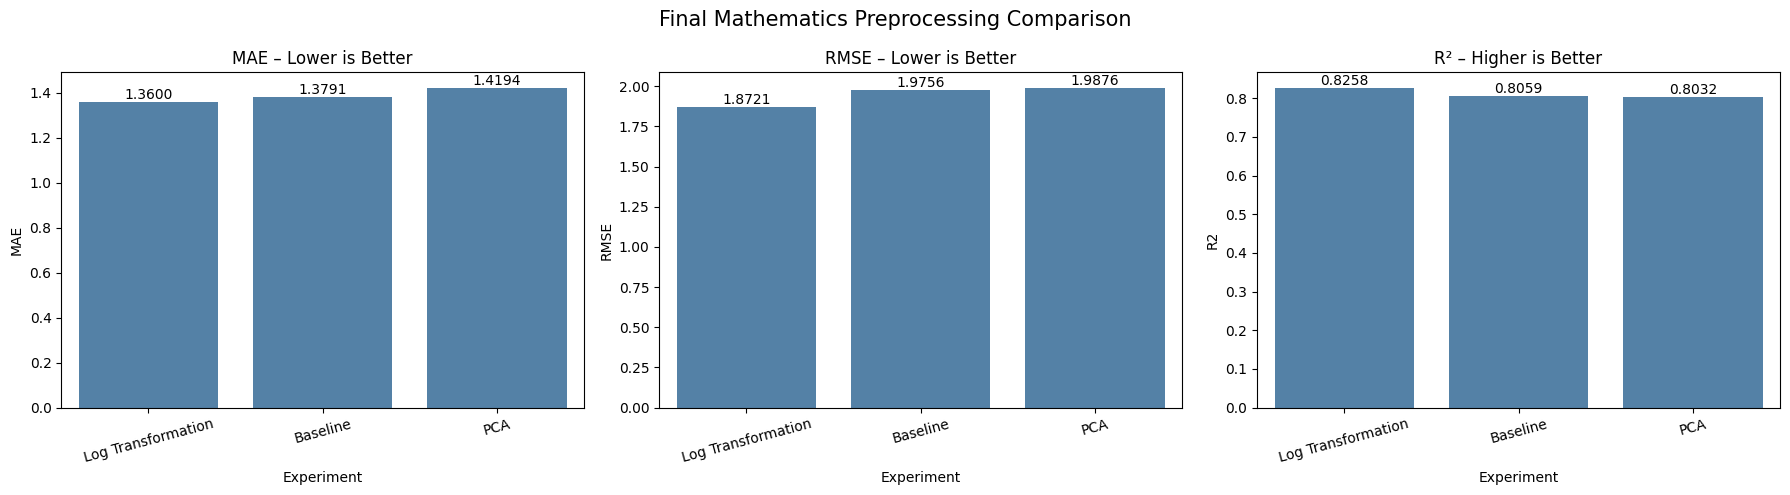

In [219]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = [
    ("MAE", "MAE – Lower is Better"),
    ("RMSE", "RMSE – Lower is Better"),
    ("R2", "R² – Higher is Better")
]

for ax, (metric, title) in zip(axes, metrics):

    sns.barplot(
        data=final_results,
        x="Experiment",
        y=metric,
        ax=ax,
        color="steelblue"
    )

    ax.set_title(title)
    ax.tick_params(axis="x", rotation=15)

    for container in ax.containers:
        ax.bar_label(container, fmt="%.4f")

plt.suptitle(
    "Final Mathematics Preprocessing Comparison",
    fontsize=15
)

plt.tight_layout()
save_plot("20_final_preprocessing_comparison.png")

Automatically select the best configuration

In [220]:
from sklearn.base import clone

best = final_results.iloc[0]
best_name = best["Experiment"]

preprocessor_options = {
    "Baseline": baseline_preprocessor,
    "Log Transformation": transformation_preprocessor,
    "PCA": pca_preprocessor
}

selected_preprocessor = clone(
    preprocessor_options[best_name]
)

print("=" * 50)
print("FINAL PREPROCESSING SELECTION")
print("=" * 50)

print("Best configuration:", best_name)
print("Numerical scaler: RobustScaler")
print("Categorical encoder: OneHotEncoder")
print(f"MAE:  {best['MAE']:.4f}")
print(f"RMSE: {best['RMSE']:.4f}")
print(f"R²:   {best['R2']:.4f}")

print("\nSelected preprocessor:")
print(selected_preprocessor)

FINAL PREPROCESSING SELECTION
Best configuration: Log Transformation
Numerical scaler: RobustScaler
Categorical encoder: OneHotEncoder
MAE:  1.3600
RMSE: 1.8721
R²:   0.8258

Selected preprocessor:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', RobustScaler())]),
                                 ['age', 'Medu', 'Fedu', 'traveltime',
                                  'studytime', 'failures', 'famrel', 'freetime',
                                  'goout', 'Dalc', 'Walc', 'health', 'G1',
                                  'G2']),
                                ('absences_log',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('log',
                

Save the final comparison and selected configuration

In [221]:
import joblib

final_results.to_csv(
    processed_dir / "20_final_preprocessing_results.csv",
    index=False
)

joblib.dump(
    {
        "experiment": best_name,
        "preprocessor": selected_preprocessor,
        "MAE": float(best["MAE"]),
        "RMSE": float(best["RMSE"]),
        "R2": float(best["R2"])
    },
    processed_dir / "20_selected_preprocessing_configuration.joblib"
)

print("Final comparison and configuration saved.")

Final comparison and configuration saved.
